In [3]:
import os, sys, time, math, gc, mne, json
import torch
import json
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import pandas as pd
import scipy.signal as signal
from pathlib import Path
from inspect import signature
from scipy.stats import zscore 

from sklearn.metrics import r2_score

from intanutil import intan_rhd as intan

In [8]:
DATA_ROOT = "D:\\Becca\\Data\\PN\\"

# Styling

9


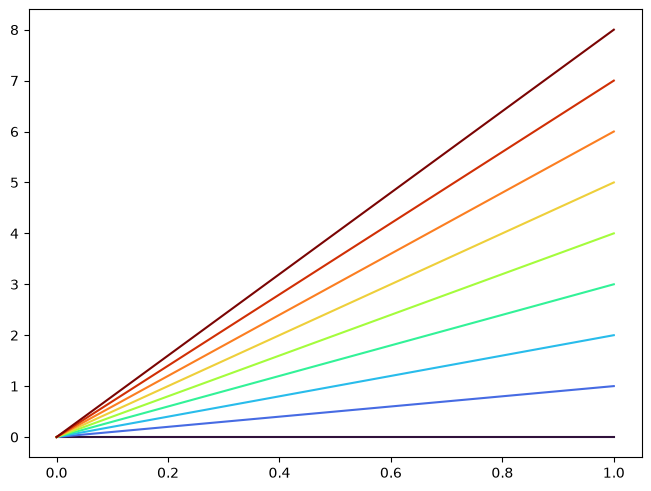

In [4]:
# pick a colormap
cmap = plt.get_cmap('turbo')
color_list = cmap(np.linspace(0,1,9))
fig, ax = plt.subplots(layout='constrained')

for i, color in enumerate(color_list):
    ax.plot([0, i], color=color_list[i])

print(len(color_list))
color_list = color_list[1:]


# NSR004002 (P1)

In [9]:
### P1 data from JSON file
file_path = os.path.join(DATA_ROOT, "NSR004002", "Inference block_blue_loc4_21_1742411126663_250319_150526")

with open(os.path.join(file_path, 'inference_stats.json')) as json_file:
    data = json.load(json_file)

In [33]:
print(f"Successful Trials {data['success']} of {data['total']}")
print(f"Success rate {data['accuracy']}")

correct = np.zeros(4)
total = np.zeros(4)

for x,y in zip(data['labels'], data['predictions']):
    total[x] += 1
    if (x == y):
        total[x] += 1

# weighted accuracy
print(f"Class Weighted Accuracy: {np.sum(correct / total)}")

Successful Trials 21 of 34
Success rate 0.6176470588235294
 Class Weighted Accuracy: 0.0


([<matplotlib.axis.YTick at 0x1eec8187650>,
 [Text(0, 0.5, 'Down'),
  Text(0, 1.5, 'Right'),
  Text(0, 2.5, 'Up'),
  Text(0, 3.5, 'Left')])

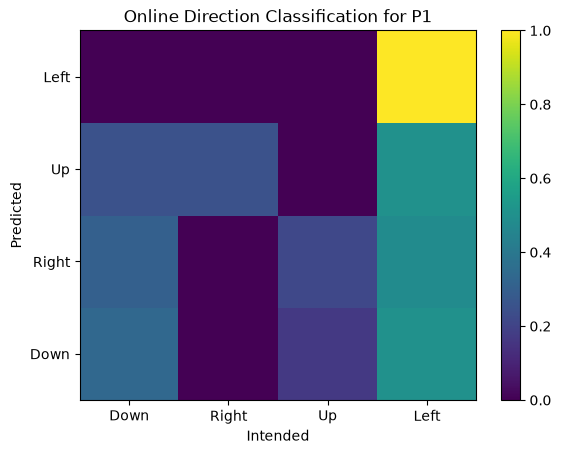

In [10]:
conf =data['confusion_matrix']
conf = np.transpose(np.transpose(conf) /np.sum(conf, axis=1))
conf = np.fliplr(conf)
plt.pcolor(conf)
plt.colorbar()
plt.title("Online Direction Classification for P1")
plt.xlabel("Intended")
plt.ylabel("Predicted")

plt.xticks([0.5, 1.5, 2.5, 3.5], labels =['Down', 'Right', 'Up', 'Left']  )
plt.yticks([0.5, 1.5, 2.5, 3.5], labels =['Down', 'Right', 'Up', 'Left'] )

# NSR004003 (P2)

In [12]:
file_path = os.path.join(DATA_ROOT, "NSR004003","Inference block_FIH0050blue_loc4_9_1744228833127_250409_160033")

with open(os.path.join(file_path, 'inference_stats.json')) as json_file:
    data = json.load(json_file)

In [34]:
print(f"Successful Trials {data['success']} of {data['total']}")
print(f"Success rate {data['accuracy']}")

correct = np.zeros(4)
total = np.zeros(4)

for x,y in zip(data['labels'], data['predictions']):
    total[x] += 1
    if (x == y):
        total[x] += 1

# weighted accuracy
print(f"Class Weighted Accuracy: {np.sum(correct / total)}")

Successful Trials 21 of 34
Success rate 0.6176470588235294
Class Weighted Accuracy: 0.0


[[2, 2, 0, 1], [4, 5, 0, 6], [0, 0, 4, 0], [0, 0, 0, 10]]


([<matplotlib.axis.YTick at 0x1eec8236b10>,
 [Text(0, 0.5, 'Down'),
  Text(0, 1.5, 'Right'),
  Text(0, 2.5, 'Up'),
  Text(0, 3.5, 'Left')])

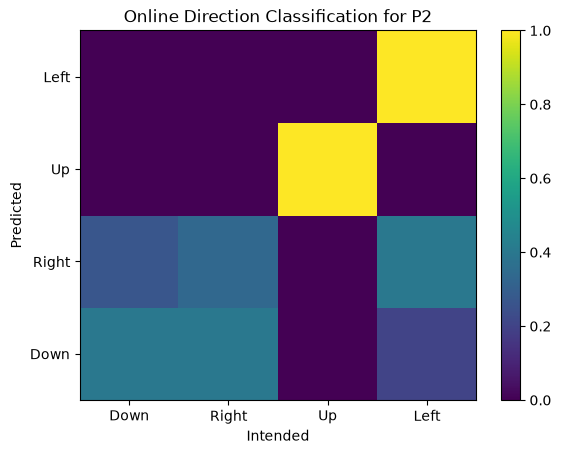

In [21]:
conf =data['confusion_matrix']
print(conf)
conf = np.transpose(np.transpose(conf) /np.sum(conf, axis=1))
#conf = np.fliplr(conf)

plt.pcolor(conf)
plt.colorbar()
plt.title("Online Direction Classification for P2")
plt.xlabel("Intended")
plt.ylabel("Predicted")
plt.xticks([0.5, 1.5, 2.5, 3.5], labels =['Down', 'Right', 'Up', 'Left']  )
plt.yticks([0.5, 1.5, 2.5, 3.5], labels =['Down', 'Right', 'Up', 'Left'] )

# NSR004004 (P3)

In [54]:
subject_root = os.path.join(DATA_ROOT, "NSR004004")

trial = "center-out-easy-inference_FIH0068__2_1753288323373_250723_163203"
trial = "center-out-easy-block2_FIH0068__1_1753287064855_250723_161104"

with open( os.path.join(subject_root, trial, 'task_ui_events.jsonl'), 'r') as json_file:
    json_list = list(json_file)


cursor_x = []
cursor_y = []
cursor_times = []
completion_times = []
start_times = []
timeout_times = []
for json_item in json_list:
    result = json.loads(json_item)
    if('type' in result.keys()):
        if (result['type'] == 'event'):
            if(result['data']['type'] == 'movement'):
                cursor_x.append(result['data']['extra']['x'])
                cursor_y.append(result['data']['extra']['y'])
                cursor_times.append(result['microsecond'])
            elif(result['data']['type'] == 'targets_complete'):
                completion_times.append(result['microsecond'])
            elif(result['data']['type'] == 'target_initialized'):
                start_times.append(result['microsecond'])
            elif(result['data']['type'] == 'timeout'):
                timeout_times.append(result['microsecond'])

t0 = cursor_times[0]
cursor_times = np.asarray(cursor_times)

FileNotFoundError: [Errno 2] No such file or directory: 'D:\\Becca\\Data\\PN\\NSR004004\\infer-veasy-hover_FIH0093_webgrid_2_1765992257513_251217_172417\\task_ui_events.jsonl'

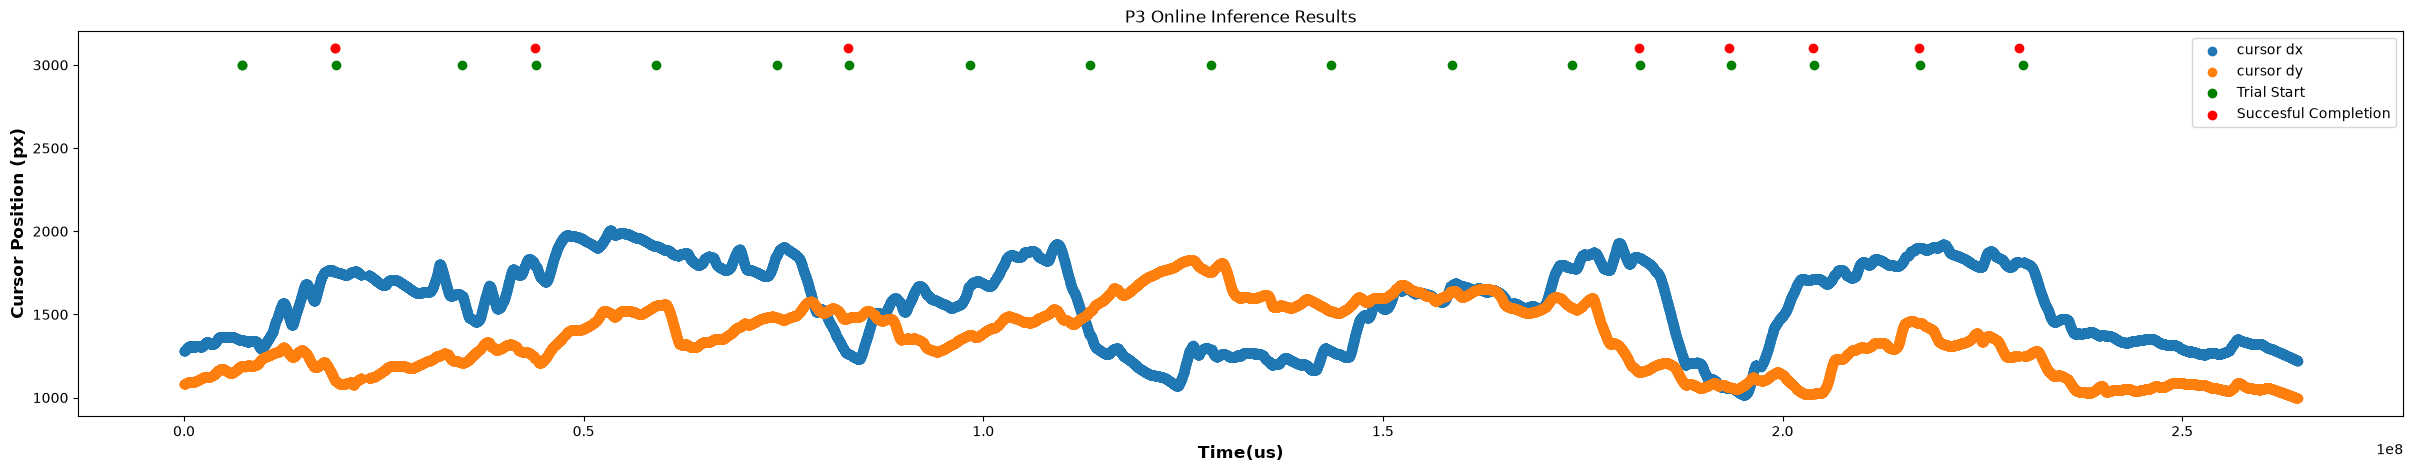

In [36]:
# Manually Check 
fig,ax = plt.subplots(1,1,figsize=(30,5))
plt.scatter((cursor_times-t0), cursor_x, label="cursor dx")
plt.scatter((cursor_times-t0), cursor_y, label="cursor dy")

s5_fs = 100
for point in start_times:
    plt.scatter([(point-t0)], [3000], color='green')
for point in completion_times:
    plt.scatter([(point-t0)], [3100], color='red')

for point in start_times[0:1]:
    plt.scatter([(point-t0)], [3000], color='green', label = "Trial Start" )
for point in completion_times[0:1]:
    plt.scatter([(point-t0)], [3100], color='red', label = "Succesful Completion")

#for point in start_times[0:1]:
#    plt.plot([(point-t0)]*2, [0,3000], color='green', linewidth="4", label="Task Start")
#for point in completion_times[0:1]:
#    plt.plot([(point-t0)]*2, [0,3000], color='red', label="Task Completed")

ax.set_xlabel("Time(us)",weight="bold", size='large')
ax.set_ylabel('Cursor Position (px)',weight="bold", size='large')
plt.title("P3 Online Inference Results")
plt.legend()

In [44]:
sstart_times = [start_times[0],start_times[2],start_times[5], start_times[12], start_times[13], start_times[14], start_times[15],start_times[16]]
time_elapsed = 1/1000000 * (np.asarray(completion_times) - np.asarray(sstart_times))
print(time_elapsed) 
print(np.median(time_elapsed), np.std(time_elapsed))

[11.621694  9.144546  8.972878  8.364494 11.133602 10.281583 13.181995
 12.325456]
10.7075925 1.6136463600816475


Text(0, 0.5, 'Y')

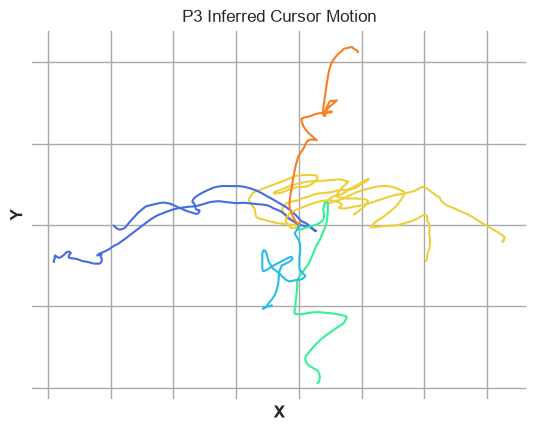

In [52]:
cursor_times = np.asarray(cursor_times)
cursor_x = np.asarray(cursor_x)
cursor_y = np.asarray(cursor_y)

## really this can be combined with the previous one 
for trial in range(len(sstart_times)):
    
    sidx = np.where(cursor_times < sstart_times[trial])[0][-1]
    eidx = np.where(cursor_times > completion_times[trial])[0][0]
    x = cursor_x[sidx:eidx] - cursor_x[sidx]
    y = cursor_y[sidx:eidx]- cursor_y[sidx]

    angle = 180/np.pi* np.atan2(  y[-1] - y[0], x[-1] - x[0] ) 
        
    angle_class = int( np.rint(angle / 45) + 4)
    
    if angle_class == 8:
        angle_class = 0
        
    plt.plot(x,y, color=color_list[angle_class] )

plt.title("P3 Inferred Cursor Motion")
plt.tick_params(
    axis='x',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    bottom=False,      # ticks along the bottom edge are off
    top=False,         # ticks along the top edge are off
    labelbottom=False) # labels along the bottom edge are off
plt.tick_params(
    axis='y',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    left=False,        # ticks along the bottom edge are off
    right=False,        # ticks along the top edge are off
    labelleft=False) # labels along the bottom edge are off
plt.xlabel("X", weight="bold")
plt.ylabel("Y", weight="bold")

# NSR004005 (P4)

# NSR102005 (P5)

# NSR102005 (P5) Imagined

# Figure 

In [46]:
def s5_load_data(json_filename, tasktype = "INFER"):
    
    subject_list = []
    time_list = []
    status_list = []
    target_list = []
    start_pos_list = []
    end_pos_list = []
    type_list = []
    with open( json_filename, 'r') as json_file:
        json_list = list(json_file)

    s5_fs = 10
    t0 = None
    state = "REST"
    for json_item in json_list:
        result = json.loads(json_item)
        if('type' in result.keys()):
            if (result['type'] == 'event'):
                if(result['data']['type'] == 'target_initialized'):
                    match state:
                        case "TRIAL":
                            status_list.append("FAIL")
                            time_list.append(-1)
                            subject_list.append("P4")
                            end_pos_list.append(np.asarray([result["data"]["cursor_position"]["x"],result["data"]["cursor_position"]["y"]]) )
                            type_list.append(tasktype)
                            
                            t0 = result['microsecond']
                            state = "TRIAL"
                            start_pos_list.append(np.asarray([result["data"]["cursor_position"]["x"],result["data"]["cursor_position"]["y"]]) )
                            target_list.append(np.asarray([result["data"]["extra"]["coordinate_location"]["x"],result["data"]["extra"]["coordinate_location"]["y"]] ) )

                        case "REST":
                            t0 = result['microsecond']
                            state = "TRIAL"
                            start_pos_list.append(np.asarray([result["data"]["cursor_position"]["x"],result["data"]["cursor_position"]["y"]]) )
                            target_list.append(np.asarray([result["data"]["extra"]["coordinate_location"]["x"],result["data"]["extra"]["coordinate_location"]["y"]]) )


                        case _ :
                            raise ValueError(f"INVALID STATE")

                
                elif(result['data']['type'] == 'targets_complete'):
                    match state:
                        case "REST":
                            raise ValueError(f"SHOULD NOT BE IN REST")
                        case "TRIAL":
                            state = "REST"
                            dt = (result['microsecond'] - t0)/1000000
                            status_list.append("SUCCESS")
                            time_list.append(dt)
                            subject_list.append("P4")
                            end_pos_list.append(np.asarray( [result["data"]["cursor_position"]["x"],result["data"]["cursor_position"]["y"]]) )
                            type_list.append(tasktype)
    if (len(target_list) == len(time_list) ):
        target_list.append(None)
        start_pos_list.append(None)
    df = pd.DataFrame({
                        'Subject': subject_list,
                        'time': time_list,
                        'status': status_list,
                        'Target': target_list[:-1],
                        'Start': start_pos_list[:-1],
                        'End': end_pos_list,
                        'Block Type': type_list        
                        })
    
    return df

In [47]:
def s4_load_data(json_filename, tasktype = "INFER"):
    
    subject_list = []
    time_list = []
    status_list = []
    target_list = []
    start_pos_list = []
    end_pos_list = []
    type_list = []
    with open( json_filename, 'r') as json_file:
        json_list = list(json_file)

    s5_fs = 10
    t0 = None
    state = "REST"
    for json_item in json_list:
        result = json.loads(json_item)
        if('type' in result.keys()):
            if (result['type'] == 'event'):
                if(result['data']['type'] == 'target_initialized'):
                    match state:
                        case "TRIAL":
                            status_list.append("FAIL")
                            time_list.append(-1)
                            subject_list.append("P3")
                            end_pos_list.append(None )
                            type_list.append(tasktype)
                            
                            t0 = result['microsecond']
                            state = "TRIAL"
                            start_pos_list.append(None )
                            target_list.append(None )

                        case "REST":
                            t0 = result['microsecond']
                            state = "TRIAL"
                            start_pos_list.append(None )
                            target_list.append(None )

                        case _ :
                            raise ValueError(f"INVALID STATE")

                
                elif(result['data']['type'] == 'targets_complete'):
                    match state:
                        case "REST":
                            raise ValueError(f"SHOULD NOT BE IN REST")
                        case "TRIAL":
                            state = "REST"
                            dt = (result['microsecond'] - t0)/1000000
                            status_list.append("SUCCESS")
                            time_list.append(dt)
                            subject_list.append("P3")
                            end_pos_list.append(None )
                            type_list.append(tasktype)
    if (len(target_list) == len(time_list) ):
        target_list.append(None)
        start_pos_list.append(None)
    df = pd.DataFrame({
                        'Subject': subject_list,
                        'time': time_list,
                        'status': status_list,
                        'Target': target_list[:-1],
                        'Start': start_pos_list[:-1],
                        'End': end_pos_list,
                        'Block Type': type_list        
                        })
    
    return df

In [48]:
def nsr1002005_pull_data_from_file(json_filename, trial_type = "INFER", NAME = "P5", FAILURE_TIME_THRSH = 60):

    subject_list = []
    time_list = []
    status_list = []
    target_list = []
    start_pos_list = []
    end_pos_list = []
    type_list = []
    

    with open( json_filename, 'r') as json_file:
        json_list = list(json_file)

        t0 = None
        state = "REST"

        #try:
        for json_item in json_list:
            result = json.loads(json_item)
            if('type' in result.keys()):
                if (result['type'] == 'event'):
                    if(result['data']['type'] == 'target_initialized'):
                        match state:
                            case "REST":
                                t0 = result['microsecond']
                                state = "TRIAL"

                                target_list.append(None)
                                start_pos_list.append(None)
                            case "TRIAL":
                                status_list.append("FAIL")
                                time_list.append(-1)
                                subject_list.append(NAME)
                                type_list.append(trial_type)
                                end_pos_list.append(None)


                                t0 = result['microsecond']
                                target_list.append(None)
                                start_pos_list.append(None)

                            case _: 
                                raise ValueError(f"The state {state} is not valid.")

                    elif(result['data']['type'] == 'targets_complete'):
                        match state:
                            case "REST":
                                raise ValueError(f"SHOULD NOT BE IN REST")
                            case "TRIAL":
                                dt = (result['microsecond'] - t0)/1000000
                                
                                status_list.append("SUCCESS")
                                time_list.append(dt)
                                subject_list.append(NAME)
                                type_list.append(trial_type)
                                end_pos_list.append(None)

                                t0 = None
                                state = "REST"
                            case _: 
                                raise ValueError(f"The state {state} is not valid.")
    if (len(target_list) == len(time_list) ):
        target_list.append(None)
        start_pos_list.append(None)
    df = pd.DataFrame({
                        'Subject': subject_list,
                        'time': time_list,
                        'status': status_list,
                        'Target': target_list[:-1],
                        'Start': start_pos_list[:-1],
                        'End': end_pos_list,
                        'Block Type': type_list        
                        })
    
    return df

In [57]:
# Put all data into dataframe
df_list = []

subject_root = "D:\\Becca\\Data\\PN\\NSR004005\\"
trial = "infer-veasy-hover_FIH0093_webgrid_1_1765991935483_251217_171855"
P4_file = os.path.join(subject_root, trial, trial, 'task_ui_events.jsonl')
p4_df = s5_load_data(P4_file, "INFER")
p4_df = p4_df[p4_df["status"] == "SUCCESS"]
p4_df = p4_df[(np.abs(zscore(p4_df["time"])) < 3) &(p4_df["time"] > 0.2) ]
df_list.append(p4_df)

subject_root = "D:\\Becca\\Data\\PN\\NSR004005\\"
trial = "infer-veasy-hover_FIH0093_webgrid_2_1765992257513_251217_172417"
P4_file = os.path.join(subject_root, trial, trial, 'task_ui_events.jsonl')
p4_df = s5_load_data(P4_file, "INFER")
p4_df = p4_df[p4_df["status"] == "SUCCESS"]
p4_df = p4_df[(np.abs(zscore(p4_df["time"])) < 3) &(p4_df["time"] > 0.2) ]
df_list.append(p4_df)


trial = "train-veasy-hover_FIH0093_webgrid_2_1765990632034_251217_165712"
P4_file = os.path.join(subject_root, trial, trial, 'task_ui_events.jsonl')
p4_df = s5_load_data(P4_file, "TRAIN")
p4_df = p4_df[p4_df["status"] == "SUCCESS"]
p4_df = p4_df[(np.abs(zscore(p4_df["time"])) < 3)]
df_list.append(p4_df)



subject_root = "D:\\Becca\\Data\\PN\\NSR004004\\"
trial = "center-out-easy-inference_FIH0068__2_1753288323373_250723_163203"
P3_file = os.path.join(subject_root, trial, 'task_ui_events.jsonl')
p3_df = s4_load_data(P3_file, "INFER")
p3_df = p3_df[p3_df["status"] == "SUCCESS"]
p3_df = p3_df[(np.abs(zscore(p3_df["time"])) < 3)]
df_list.append(p3_df)

trial = "center-out-easy-block1_FIH0068__1_1753286802143_250723_160642"
P3_file = os.path.join(subject_root, trial, 'task_ui_events.jsonl')
p3_df = s4_load_data(P3_file, "TRAIN")
p3_df = p3_df[(np.abs(zscore(p3_df["time"])) < 3)]
df_list.append(p3_df)

p5_trial = "D:\\Becca\\Data\\PN\\NSR-102-005\\Session2\\29-DEC-2025\\webgrid-easy-random_FIH0117_infer_1_1767105022887_251230_143022\\"
p5_file = os.path.join(p5_trial,'task_ui_events.jsonl')
p5_df = nsr1002005_pull_data_from_file(p5_file, "INFER", "P5a")
p5_df = p5_df[p5_df["status"] == "SUCCESS"]
p5_df = p5_df[(np.abs(zscore(p5_df["time"])) < 3)]
df_list.append(p5_df)

p5_trial ="D:\\Becca\\Data\\PN\\NSR-102-005\\Session2\\29-DEC-2025\\webgrid-medium-random_FIH0117_train_1_1767103993233_251230_141313\\"
p5_file = os.path.join(p5_trial,'task_ui_events.jsonl')
p5_df = nsr1002005_pull_data_from_file(p5_file, "TRAIN", "P5a")
p5_df = p5_df[(np.abs(zscore(p5_df["time"])) < 3)]
df_list.append(p5_df)

p5_trial ="D:\\Becca\\Data\\PN\\NSR-102-005\\Session8\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767206977752_251231_184937\\"
p5_file = os.path.join(p5_trial,'task_ui_events.jsonl')
p5_df = nsr1002005_pull_data_from_file(p5_file, "INFER", "P5b")
p5_df = p5_df[(np.abs(zscore(p5_df["time"])) < 3)]
df_list.append(p5_df)

p5_trial ="D:\\Becca\\Data\\PN\\NSR-102-005\\Session8\\29-DEC-2025\\webgrid-hard_FIH0117_train_1_1767203809930_251231_175649\\"
p5_file = os.path.join(p5_trial,'task_ui_events.jsonl')
p5_df = nsr1002005_pull_data_from_file(p5_file, "TRAIN", "P5b")
p5_df = p5_df[(np.abs(zscore(p5_df["time"])) < 3)]
df_list.append(p5_df)



all_df = pd.concat(df_list)

C:\Users\Becca\AppData\Local\Temp\ipykernel_34048\3635976210.py:51: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(data=all_df[all_df['Block Type'] == "INFER"],
C:\Users\Becca\AppData\Local\Temp\ipykernel_34048\3635976210.py:72: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(data=all_df[all_df['Block Type'] == "TRAIN"],


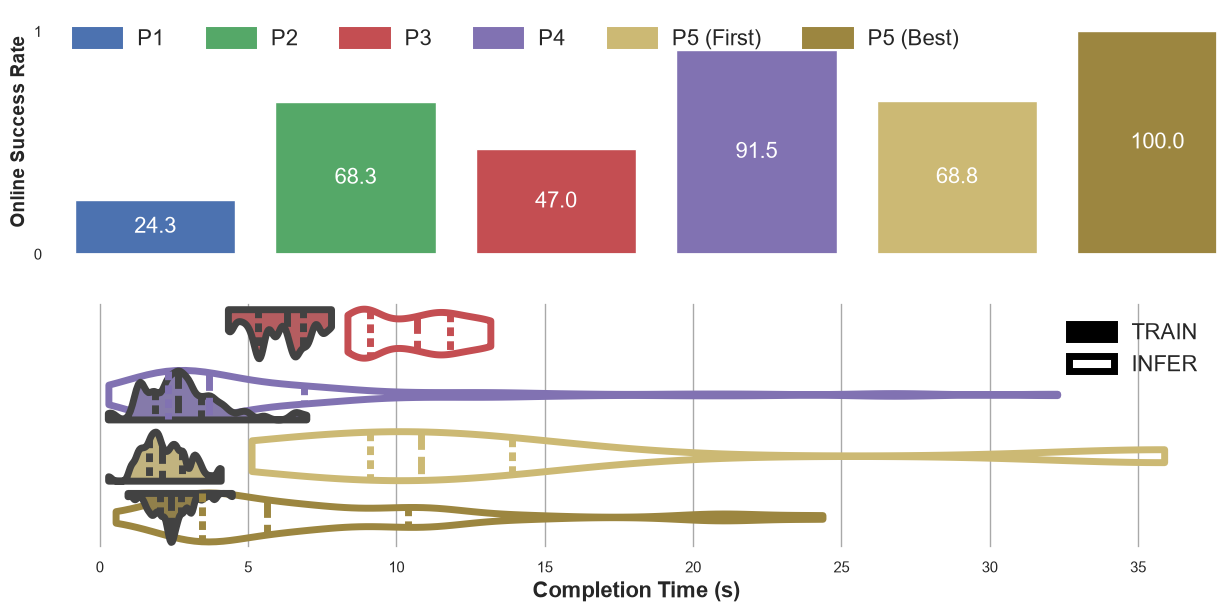

In [56]:
sns.set(rc={
    "axes.facecolor": "#FFFFFF",  # change this to any color you want
    "grid.color": "#A9A9A9", 
})

fig,ax = plt.subplots(2,1, figsize = (15,7),frameon=False)


participants = np.asarray([1,2,3,4,5,6] )
success_rate = [.243, .683, 0.47, np.round(75/82,3), np.round(11/16,3), 1.0]
color_set =  ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974','#9C8640']

ax0_bars = ax[0].bar(participants,success_rate,color=color_set)


for bar in ax0_bars:
    height = bar.get_height()
    ax[0].text(
        bar.get_x() + bar.get_width() / 2,
        height / 2,                  # inside the bar
        f'{np.round(100*height,3)}',
        ha='center',
        va='center',
        color='white',
        fontsize=16
    )

ax[0].set_xticks([1,2,3,4,5] )
#ax[0].set_xticklabels(["P1", "P2","P3","P4","P5"], weight="bold")
ax[0].set_xticks([])
ax[0].set_ylim(0,1.1)
ax[0].set_yticks([0,1])
ax[0].set_yticklabels(["0","1"])
ax[0].set_ylabel("Online Success Rate",fontsize=14, weight="bold")
ax[0].set_xlim([0.5,6.3] )


legend0_elements = [
    Patch(facecolor=color_set[0], edgecolor=color_set[0], label='P1', linewidth=5),
    Patch(facecolor=color_set[1], edgecolor=color_set[1], label='P2', linewidth=5),
    Patch(facecolor=color_set[2], edgecolor=color_set[2], label='P3', linewidth=5),
    Patch(facecolor=color_set[3], edgecolor=color_set[3], label='P4', linewidth=5),
    Patch(facecolor=color_set[4], edgecolor=color_set[4], label='P5 (First)', linewidth=5),
    Patch(facecolor=color_set[5], edgecolor=color_set[5], label='P5 (Best)', linewidth=5),

]
ax[0].grid(False)
ax[0].legend(handles=legend0_elements, fontsize=16, frameon=False, ncol=6)

#---------------------
sns.violinplot(data=all_df[all_df['Block Type'] == "INFER"],
            y="Subject", 
            order=["P3", "P4", "P5a", "P5b"], 
            x="time", 
            hue="Subject",
            palette={
            'P3': color_set[2],
            'P4': color_set[3],
            "P5a": color_set[4],
            "P5b": color_set[5],
            },
            split=False, 
            inner="quart", 
            cut= 0, 
            bw_adjust = 0.5, 
            fill=False, 
            ax=ax[1], 
            linewidth=5, 
            scale='width')


sns.violinplot(data=all_df[all_df['Block Type'] == "TRAIN"],
            y="Subject", 
            order=["P3", "P4", "P5a", "P5b"], 
            x="time", 
            hue="Subject",
            palette={
            'P3': color_set[2],
            'P4': color_set[3],
            "P5a": color_set[4],
            "P5b": color_set[5],
            },
            split=True, 
            inner="quart", 
            cut= 0, 
            bw_adjust = 0.3, 
            fill=True, 
            ax=ax[1], 
            linewidth=5, 
            scale='width')


#ax[1].set_xlim([-2.5,2.3] )
#ax[1].set_xticks([-2,-1,0,1,2] )
#ax[1].set_xticklabels(["P1", "P2","P3","P4","P5"])
ax[1].set_xlabel("Completion Time (s)",fontsize=16, weight="bold")
ax[1].set_yticks([])
ax[1].set_ylabel("")

legend_elements = [
    Patch(facecolor='black', edgecolor='black', label='TRAIN', linewidth=5),
    Patch(facecolor='none', edgecolor='black', label='INFER', linewidth=5)
]

ax[1].legend(handles=legend_elements, fontsize=16, frameon=False)
